# Predicción Lineal

**22.46 Procesamiento Adaptativo de Señales Aleatorias — Trabajo Práctico 3**

# Grupo N° 5

| Integrante | Legajo |
|---|---|
| Albertine Gjøs | 69531 |
| Marek Myrebøe-Engels | 69476 |

In [161]:
from scipy import signal
import numpy as np
import soundfile as sf
import os
from IPython.display import Audio, display
import matplotlib.pyplot as plt
from scipy.linalg import solve_toeplitz
from scipy.signal.windows import hann
from scipy.signal import welch


## 1. Grabación de Voz

In [162]:
# Should I normalize signals?
fs = 16000

a, fs_a = sf.read("data/a.wav", always_2d=True)
sh, fs_sh= sf.read("data/sh.wav", always_2d=True)

a = a.mean(axis=1)
a = signal.resample_poly(a, fs, fs_a)
a = a[0:1*fs] # 1 segundo
display(Audio(a, rate=fs))

sh = sh.mean(axis=1)
sh = signal.resample_poly(sh, fs, fs_sh)
sh = sh[0:fs] # 1 segundo
display(Audio(sh, rate=fs))

## 2. Predicción Lineal 

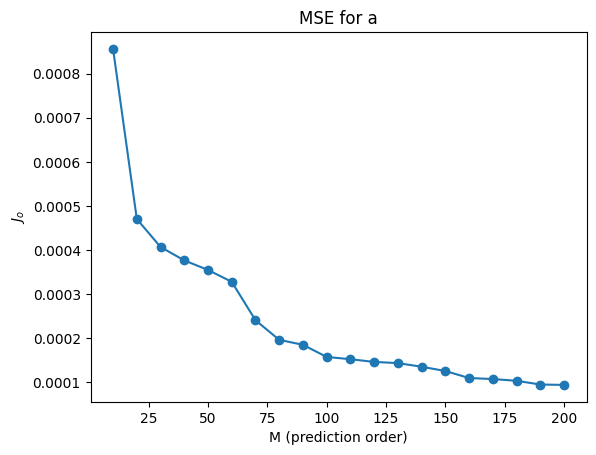

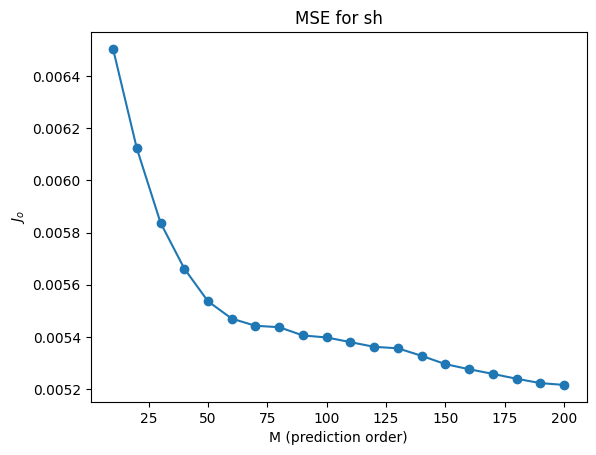

In [163]:
# Predicción forward
# Plot MSE J
# Dos codos para a y un para sh
# Recomendacion: Investigen error ef(n)
# ef(n) = x(n) + aH(n)x(n-1)
# Not investigated ef.......


for x, name in zip([a, sh], ['a', 'sh']):
    M_values = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200]

    N = len(x)

    J = []

    for M in M_values:

        # Past samples: x[n-1], ..., x[n-M]
        X = np.array([
            x[n-M:n][::-1]
            for n in range(M, N)
        ])

        # Desired/current samples: x[n]
        d = x[M:N]

        # Autocorrelation matrix
        R = X.conj().T @ X / len(d)

        # Cross-correlation vector
        r = X.conj().T @ d / len(d)

        # Optimal predictor coefficients
        ao = np.linalg.solve(R, -r)

        # Minimum MSE
        sigma_x2 = np.vdot(d, d).real / len(d)
        Jo = sigma_x2 - np.vdot(-r, ao).real

        J.append(Jo)

    plt.plot(M_values, J, "-o")
    plt.xlabel("M (prediction order)")
    plt.ylabel(r"$J_o$")
    plt.title(f'MSE for {name}')
    plt.show()


## 3. Dominio de Frecuencia

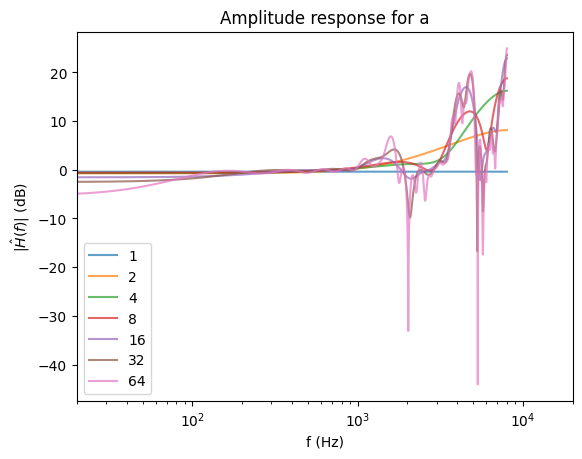

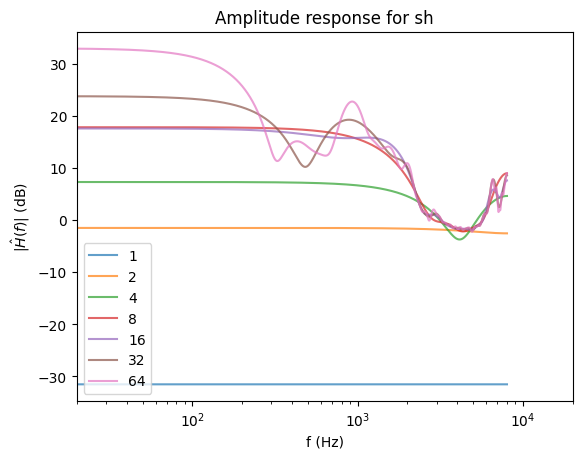

In [ ]:
# Grabaciones en dominio de frecuencia
# representen la respuesta en frecuencia H(ejω) del filtro del error de predicción ā (no el filtro predictor a) 
# para M = 1, 2, 4, 8, 16, 32, 64. 
Ms = [1, 2, 4, 8, 16, 32, 64]

def finding_filter(x, M):
    X = np.array([
        x[n-M:n][::-1]
        for n in range(M, N)
    ])

    # Desired/current samples: x[n]
    d = x[M:N]

    # Autocorrelation matrix
    R = X.conj().T @ X / len(d)

    # Cross-correlation vector
    r = X.conj().T @ d / len(d)

    # Optimal predictor coefficients
    ao = np.linalg.solve(R, -r)

    return ao.real

aos_a = []
aos_sh = []

for aos, x, name in zip([aos_a, aos_sh], [a, sh], ['a', 'sh']):
    for M in Ms: 
        aos.append(finding_filter(x, M))

    results = [(Ms[i], aos[i]) for i in range(len(Ms))]

    nfft = 2**16
    f = np.fft.rfftfreq(nfft, 1/fs)
    for M, wo in results:
        H = np.fft.rfft(wo, nfft)
        plt.semilogx(f, 20*np.log10(np.abs(H)), label=M, alpha=0.7)
    plt.xlim(20, 20000)
    plt.xlabel("f (Hz)")
    plt.ylabel(r"$|\hat{H}(f)|$ (dB)")
    plt.title(f'Amplitude response for {name}')
    plt.legend()
    plt.show()


Expliquen y justifiquen los resultados obtenidos, teniendo en cuenta J(M) y ef(n).

## 4. Resinteticar y Filtrar

Donde termina el primer codo, no el segundo

In [ ]:
# resinteticen la señal de error con un modelo diseñado por ustedes (en base a lo observado en el punto 2) 
# y fíltrenla con el filtro inverso del filtro del error de predicción ā. 
# Not sure if it is the best but chose M=16 for now
ao_a = aos_a[4]
ao_sh = aos_sh[4]
for ao, x, name in zip([ao_a, ao_sh], [a, sh], ['a', 'sh']):
    x_filtered = signal.lfilter(ao, 1, x)
    display(Audio(x_filtered, rate=fs))

Escuchen el resultado y compárenlo con la grabación original. Expliquen las diferencias. Justifiquen. 

## 5. Grabación Larga

In [ ]:
# Realicen una grabación de voz a libre elección (larga) con fs = 16 kHz. Utilizando 
# ventanas de Hann de largo 50 ms con un overlap del 50%, 
# realicen la predicción forward para cada bloque con M = 12, 
# reemplacen las respectivas señales de error por un tren de impulsos (coherente entre bloques) 
# de frecuencia fs = 160 Hz, filtren las señales de error con el filtro inverso 
# del filtro del error de predicción ā, ventaneen cada resultado con una ventana de Hann, 
# y sumen los resultados en su tiempo correspondiente. 

fs = 16000
L = fs*0.5 #50 ms I hope (overlap de 50%)
D = L // 2

voice, fs_voice = sf.read("data/voice.wav", always_2d=True)

voice = voice.mean(axis=1)
voice = signal.resample_poly(voice, fs, fs_voice)
voice = voice[fs:6*fs] # 5 segundo
display(Audio(voice, rate=fs))



w = hann(L)
scale = 1.0 / (fs * np.sum(w ** 2))
starts = range(0, len(x) - L + 1, D)
acc = np.zeros(L // 2 + 1)
for s in starts:
    seg = x[s:s + L]
    seg = (seg - seg.mean()) * w                 # detrend + window
    ao = finding_filter(seg, M=12)
    e = seg - ao*seg



Escuchen la señal sumada y comparen con la grabación. ¿Qué ocurre? Justifiquen